## Data loading

In [21]:
from pathlib import Path

import h5py
import numpy as np

session_path = Path("dataset/dataset1/106r001p26_spikes.mat")

session_file = h5py.File(session_path, mode="r")

stim = session_file["stim"][:].squeeze().astype(int)

spikes_references = session_file["spikes"][:, 0]
v1_spikes = session_file[spikes_references[0]]

print("Loaded session:", session_path.name)
print("V1 stored shape:", v1_spikes.shape)
print("Stim shape:", stim.shape)

Loaded session: 106r001p26_spikes.mat
V1 stored shape: (3200, 1280, 109)
Stim shape: (3200,)


In [22]:
example_trial = 0
example_neuron = 0

raw_spike_train = v1_spikes[example_trial, :, example_neuron]
stimulus_id = stim[example_trial]
orientation_deg = (stimulus_id - 1) * 22.5

print("Example trial:", example_trial)
print("Example neuron:", example_neuron)
print("Stimulus ID:", stimulus_id)
print("Orientation:", orientation_deg, "degrees")
print("Raw values during the first 30 ms:")
print(raw_spike_train[:30].astype(int))
print("Milliseconds containing spikes:")
print(np.flatnonzero(raw_spike_train)[:30])
print("Total spikes during 1280 ms:", int(raw_spike_train.sum()))

Example trial: 0
Example neuron: 0
Stimulus ID: 3
Orientation: 45.0 degrees
Raw values during the first 30 ms:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Milliseconds containing spikes:
[111 137 154 179 213 252 256 265 285 286 293 296 305 325 332 362 404 419
 426 438 489 498 547 577 579 588 591 599 615 633]
Total spikes during 1280 ms: 44


##  From raw spikes to a tuning curve

In [23]:
# Validate the dimensions documented in the Dryad README.
n_trials, n_time_bins, n_neurons = v1_spikes.shape

assert n_trials == 3200, f"Expected 3200 trials, found {n_trials}"
assert n_time_bins == 1280, f"Expected 1280 ms per trial, found {n_time_bins}"
assert stim.shape == (n_trials,), f"Expected stim shape ({n_trials},), found {stim.shape}"

# For this session, stimulus IDs 1-8 correspond to orientations 0-157.5 degrees.
stimulus_ids = np.arange(1, 9)
orientations_deg = np.arange(0.0, 180.0, 22.5)

observed_ids, trials_per_orientation = np.unique(stim, return_counts=True)
assert np.array_equal(observed_ids, stimulus_ids), (
    f"Expected stimulus IDs {stimulus_ids.tolist()}, found {observed_ids.tolist()}"
)
assert np.all(trials_per_orientation == 400), (
    f"Expected 400 trials per orientation, found {trials_per_orientation.tolist()}"
)

# Count spikes during the 1280-ms stimulus period for every trial and neuron.
# Reading in chunks avoids loading the full approximately 3.6-GB array into memory.
trial_responses = np.empty((n_trials, n_neurons), dtype=np.float64)
chunk_size = 50

for start in range(0, n_trials, chunk_size):
    stop = min(start + chunk_size, n_trials)
    spike_chunk = v1_spikes[start:stop, :, :]
    trial_responses[start:stop, :] = spike_chunk.sum(axis=1)

# Compute the mean response and SEM across trials for every neuron and orientation.
mean_responses = np.empty((n_neurons, len(stimulus_ids)), dtype=np.float64)
sem_responses = np.empty_like(mean_responses)

for orientation_index, stimulus_id in enumerate(stimulus_ids):
    responses = trial_responses[stim == stimulus_id, :]
    mean_responses[:, orientation_index] = responses.mean(axis=0)
    sem_responses[:, orientation_index] = (
        responses.std(axis=0, ddof=1) / np.sqrt(responses.shape[0])
    )

print(f"Number of V1 neurons: {n_neurons}")
print(f"Trials per orientation: {trials_per_orientation.tolist()}")
print(f"Orientations (degrees): {orientations_deg.tolist()}")
print(f"Trial-response matrix shape: {trial_responses.shape}")
print(f"Mean-response matrix shape: {mean_responses.shape}")
print(f"SEM matrix shape: {sem_responses.shape}")

Number of V1 neurons: 109
Trials per orientation: [400, 400, 400, 400, 400, 400, 400, 400]
Orientations (degrees): [0.0, 22.5, 45.0, 67.5, 90.0, 112.5, 135.0, 157.5]
Trial-response matrix shape: (3200, 109)
Mean-response matrix shape: (109, 8)
SEM matrix shape: (109, 8)


In [24]:
example_neuron = 0
example_trial = 0

# Verify that the value calculated in trial_responses equals
# a direct sum of the 1280 raw time bins.
direct_sum = v1_spikes[example_trial, :, example_neuron].sum()
stored_sum = trial_responses[example_trial, example_neuron]

print("Direct sum from raw data:", int(direct_sum))
print("Value in trial_responses:", int(stored_sum))

assert direct_sum == stored_sum

print("\nFirst 10 trial responses for neuron 0:")
print(trial_responses[:10, example_neuron].astype(int))

print("\nMean response by orientation for neuron 0:")
for orientation, mean, sem in zip(
    orientations_deg,
    mean_responses[example_neuron],
    sem_responses[example_neuron],
):
    print(
        f"{orientation:5.1f}°: "
        f"mean = {mean:.3f} spikes, "
        f"SEM = {sem:.3f}"
    )

Direct sum from raw data: 44
Value in trial_responses: 44

First 10 trial responses for neuron 0:
[44 43 74 29 46 42 33 42 17 37]

Mean response by orientation for neuron 0:
  0.0°: mean = 34.065 spikes, SEM = 0.533
 22.5°: mean = 33.053 spikes, SEM = 0.516
 45.0°: mean = 29.060 spikes, SEM = 0.454
 67.5°: mean = 31.567 spikes, SEM = 0.488
 90.0°: mean = 41.775 spikes, SEM = 0.547
112.5°: mean = 34.508 spikes, SEM = 0.526
135.0°: mean = 31.335 spikes, SEM = 0.511
157.5°: mean = 38.883 spikes, SEM = 0.564


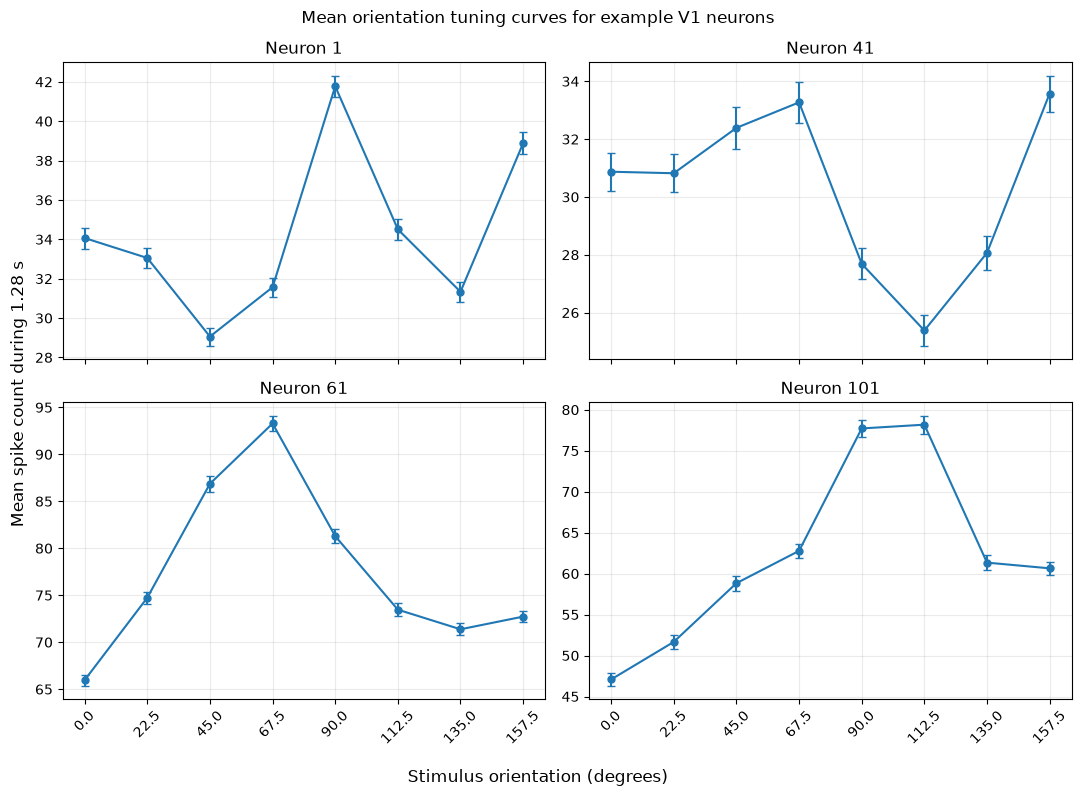

In [25]:
import matplotlib.pyplot as plt

# Four neurons selected at fixed intervals, independently of their tuning curves.
example_neuron_indices = [0, 40, 60, 100]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(11, 8),
    sharex=True,
)

for neuron_index, ax in zip(example_neuron_indices, axes.flat):
    ax.errorbar(
        orientations_deg,
        mean_responses[neuron_index],
        yerr=sem_responses[neuron_index],
        color="tab:blue",
        marker="o",
        markersize=5,
        linewidth=1.5,
        capsize=3,
    )

    # Add 1 because Python indexing starts at zero.
    ax.set_title(f"Neuron {neuron_index + 1}")
    ax.set_xticks(orientations_deg)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)

fig.suptitle("Mean orientation tuning curves for example V1 neurons")
fig.supxlabel("Stimulus orientation (degrees)")
fig.supylabel("Mean spike count during 1.28 s")

fig.tight_layout()
plt.show()

## Neuron selection

In [26]:
modulation = np.ptp(mean_responses, axis=1)
mean_sem_by_neuron = sem_responses.mean(axis=1)
overall_mean_response = mean_responses.mean(axis=1)
preferred_orientation_index = np.argmax(mean_responses, axis=1)

# Avoid division by zero in the unlikely case of a neuron with zero SEM.
tuning_score = np.divide(
    modulation,
    mean_sem_by_neuron,
    out=np.full_like(modulation, np.nan),
    where=mean_sem_by_neuron > 0,
)

ranking_values = np.nan_to_num(tuning_score, nan=-np.inf)
ranked_neuron_indices = np.argsort(ranking_values)[::-1]
top_candidate_indices = ranked_neuron_indices[:10]

print(
    f"{'Rank':>4} {'Neuron':>7} {'Index':>6} {'Score':>10} "
    f"{'Modulation':>12} {'Mean SEM':>10} {'Mean response':>14} {'Preferred':>11}"
)

for rank, neuron_index in enumerate(top_candidate_indices, start=1):
    preferred_orientation = orientations_deg[preferred_orientation_index[neuron_index]]
    print(
        f"{rank:>4} {neuron_index + 1:>7} {neuron_index:>6} "
        f"{tuning_score[neuron_index]:>10.2f} "
        f"{modulation[neuron_index]:>12.2f} "
        f"{mean_sem_by_neuron[neuron_index]:>10.3f} "
        f"{overall_mean_response[neuron_index]:>14.2f} "
        f"{preferred_orientation:>9.1f}°"
    )

Rank  Neuron  Index      Score   Modulation   Mean SEM  Mean response   Preferred
   1      38     37     139.37        17.20      0.123           4.62     157.5°
   2      21     20     129.71        32.78      0.253          10.62     157.5°
   3      98     97     129.04        29.44      0.228          13.59     135.0°
   4      81     80     121.31        52.71      0.434          31.27     135.0°
   5     104    103     109.71        24.51      0.223          10.10      90.0°
   6       5      4     106.34        12.46      0.117           4.37       0.0°
   7      11     10      95.50        42.16      0.441          26.78      90.0°
   8       6      5      94.01        22.02      0.234          12.16       0.0°
   9      80     79      91.85        26.51      0.289          17.34     135.0°
  10      22     21      87.40        26.35      0.301          15.41     157.5°


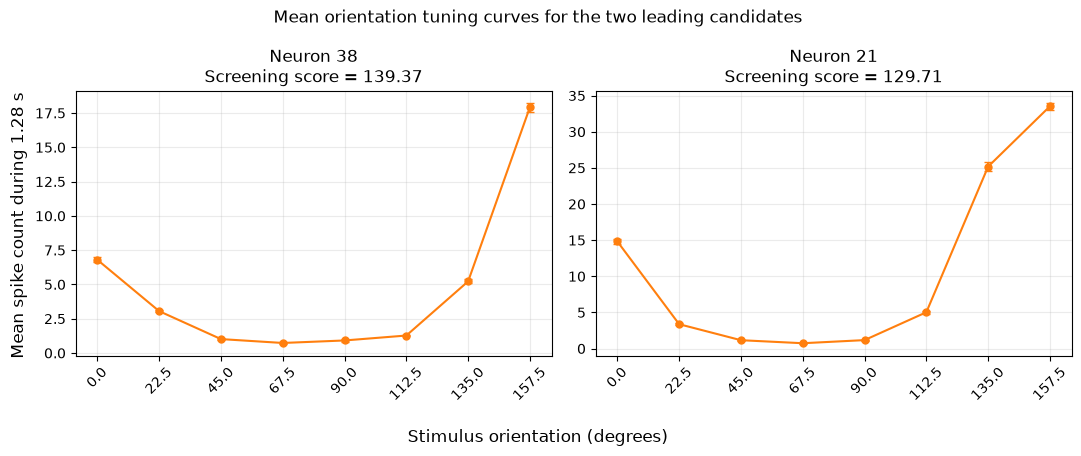

In [27]:
# Plot the two highest-ranked candidate neurons.
candidate_neuron_indices = top_candidate_indices[:2]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 4.5),
    sharex=True,
)

for neuron_index, ax in zip(candidate_neuron_indices, axes):
    ax.errorbar(
        orientations_deg,
        mean_responses[neuron_index],
        yerr=sem_responses[neuron_index],
        color="tab:orange",
        marker="o",
        markersize=5,
        linewidth=1.5,
        capsize=3,
    )

    ax.set_title(
        f"Neuron {neuron_index + 1}\n"
        f"Screening score = {tuning_score[neuron_index]:.2f}"
    )
    ax.set_xticks(orientations_deg)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)

fig.suptitle("Mean orientation tuning curves for the two leading candidates")
fig.supxlabel("Stimulus orientation (degrees)")
fig.supylabel("Mean spike count during 1.28 s")

fig.tight_layout()
plt.show()

In [28]:
# Neuron numbering in the report starts at 1, while Python indexing starts at 0.
selected_neuron_index = 20  # Neuron 21

selected_response = mean_responses[selected_neuron_index].copy()
selected_sem = sem_responses[selected_neuron_index].copy()

print("Selected neuron:", selected_neuron_index + 1)
print("Orientations (degrees):", orientations_deg)
print("Mean responses:", selected_response)
print("SEM values:", selected_sem)

Selected neuron: 21
Orientations (degrees): [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]
Mean responses: [14.8225  3.3725  1.1575  0.74    1.17    5.0275 25.1775 33.525 ]
SEM values: [0.3630696  0.12816171 0.06795793 0.05432198 0.08042961 0.22442767
 0.59014673 0.51348818]


## Polynomial regression

In [29]:
import numpy as np
from numpy.polynomial import Polynomial

# The eight measured orientations and mean responses of Neuron 21.
theta = np.asarray(orientations_deg, dtype=np.float64)
response = np.asarray(selected_response, dtype=np.float64)

assert theta.shape == response.shape == (8,)
assert np.all(np.isfinite(theta)) and np.all(np.isfinite(response))

polynomial_degrees = (1, 3, 4, 7)
polynomial_models = {}
polynomial_predictions = {}
polynomial_mse = {}

for degree in polynomial_degrees:
    model = Polynomial.fit(theta, response, deg=degree)
    predicted_at_observed_angles = model(theta)

    polynomial_models[degree] = model
    polynomial_predictions[degree] = predicted_at_observed_angles
    polynomial_mse[degree] = np.mean(
        (response - predicted_at_observed_angles) ** 2
    )

print(f"{'Model':<24} {'Degree':>6} {'Parameters':>11} {'MSE':>14}")
for degree in polynomial_degrees:
    model_name = "Linear" if degree == 1 else f"Polynomial degree {degree}"
    print(
        f"{model_name:<24} {degree:>6} {degree + 1:>11} "
        f"{polynomial_mse[degree]:>14.6e}"
    )

Model                    Degree  Parameters            MSE
Linear                        1           2   9.206642e+01
Polynomial degree 3           3           4   6.601577e+00
Polynomial degree 4           4           5   6.365859e+00
Polynomial degree 7           7           8   3.763840e-27


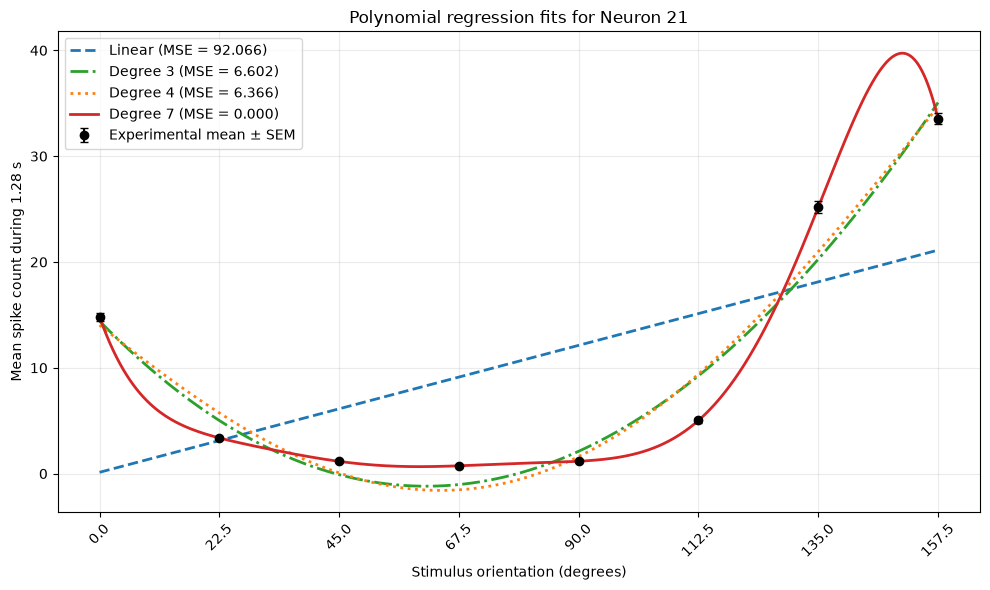

In [30]:
import matplotlib.pyplot as plt

theta_dense = np.linspace(theta.min(), theta.max(), 500)

colors = {1: "tab:blue", 3: "tab:green", 4: "tab:orange", 7: "tab:red"}
line_styles = {1: "--", 3: "-.", 4: ":", 7: "-"}

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    theta,
    response,
    yerr=selected_sem,
    color="black",
    marker="o",
    linestyle="none",
    markersize=6,
    capsize=3,
    label=r"Experimental mean $\pm$ SEM",
    zorder=5,
)

for degree in polynomial_degrees:
    model_name = "Linear" if degree == 1 else f"Degree {degree}"
    ax.plot(
        theta_dense,
        polynomial_models[degree](theta_dense),
        color=colors[degree],
        linestyle=line_styles[degree],
        linewidth=2,
        label=f"{model_name} (MSE = {polynomial_mse[degree]:.3f})",
    )

ax.set_title("Polynomial regression fits for Neuron 21")
ax.set_xlabel("Stimulus orientation (degrees)")
ax.set_ylabel("Mean spike count during 1.28 s")
ax.set_xticks(theta)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

## Gaussian regression

In [31]:
from scipy.optimize import curve_fit


def gaussian_tuning(theta_values, baseline, amplitude, preferred_orientation, width):
    """Gaussian orientation-tuning model specified in the assignment."""
    return baseline + amplitude * np.exp(
        -((theta_values - preferred_orientation) ** 2) / (2.0 * width**2)
    )


# The fit uses the same eight observations as the polynomial regressions.
assert theta.shape == response.shape == (8,)

initial_baseline = float(max(0.0, response.min()))
initial_amplitude = float(max(np.ptp(response), 1e-6))
initial_mu_values = theta.copy()
initial_sigma_values = (10.0, 30.0, 60.0)

lower_bounds = (0.0, 0.0, 0.0, 1e-6)
upper_bounds = (np.inf, np.inf, 180.0, 180.0)
fit_candidates = []

# Nonlinear optimization can converge to different local minima. We therefore
# fit from several biologically plausible starting values and retain the fit
# with the smallest MSE at the eight measured orientations.
for initial_mu in initial_mu_values:
    for initial_sigma in initial_sigma_values:
        initial_parameters = (
            initial_baseline,
            initial_amplitude,
            float(initial_mu),
            initial_sigma,
        )
        try:
            fitted_parameters, covariance = curve_fit(
                gaussian_tuning,
                theta,
                response,
                p0=initial_parameters,
                bounds=(lower_bounds, upper_bounds),
                maxfev=100_000,
            )
        except (RuntimeError, ValueError):
            continue

        candidate_prediction = gaussian_tuning(theta, *fitted_parameters)
        candidate_mse = float(np.mean((response - candidate_prediction) ** 2))

        if np.all(np.isfinite(fitted_parameters)) and np.isfinite(candidate_mse):
            fit_candidates.append((candidate_mse, fitted_parameters, covariance))

if not fit_candidates:
    raise RuntimeError("The nonlinear Gaussian fit did not converge.")

gaussian_mse, gaussian_parameters, gaussian_covariance = min(
    fit_candidates, key=lambda candidate: candidate[0]
)

B_hat, A_hat, mu_hat, sigma_hat = gaussian_parameters
gaussian_predictions = gaussian_tuning(theta, *gaussian_parameters)
gaussian_fwhm = 2.0 * np.sqrt(2.0 * np.log(2.0)) * sigma_hat

assert gaussian_predictions.shape == response.shape
assert np.all(np.isfinite(gaussian_predictions))

print("Nonlinear Gaussian fit for Neuron 21")
print(f"B (baseline):             {B_hat:.6f} spikes")
print(f"A (amplitude):            {A_hat:.6f} spikes")
print(f"mu (preferred orientation): {mu_hat:.6f} degrees")
print(f"sigma (tuning width):     {sigma_hat:.6f} degrees")
print(f"FWHM:                     {gaussian_fwhm:.6f} degrees")
print(f"MSE:                      {gaussian_mse:.6f}")

model_mse = {
    **{f"Polynomial degree {degree}": polynomial_mse[degree] for degree in polynomial_degrees},
    "Nonlinear Gaussian": gaussian_mse,
}

print("\nMSE comparison")
for model_name, mse_value in model_mse.items():
    print(f"{model_name:<24} {mse_value:.6e}")

Nonlinear Gaussian fit for Neuron 21
B (baseline):             4.255508 spikes
A (amplitude):            36.627814 spikes
mu (preferred orientation): 148.779630 degrees
sigma (tuning width):     13.020783 degrees
FWHM:                     30.661602 degrees
MSE:                      17.990826

MSE comparison
Polynomial degree 1      9.206642e+01
Polynomial degree 3      6.601577e+00
Polynomial degree 4      6.365859e+00
Polynomial degree 7      3.763840e-27
Nonlinear Gaussian       1.799083e+01


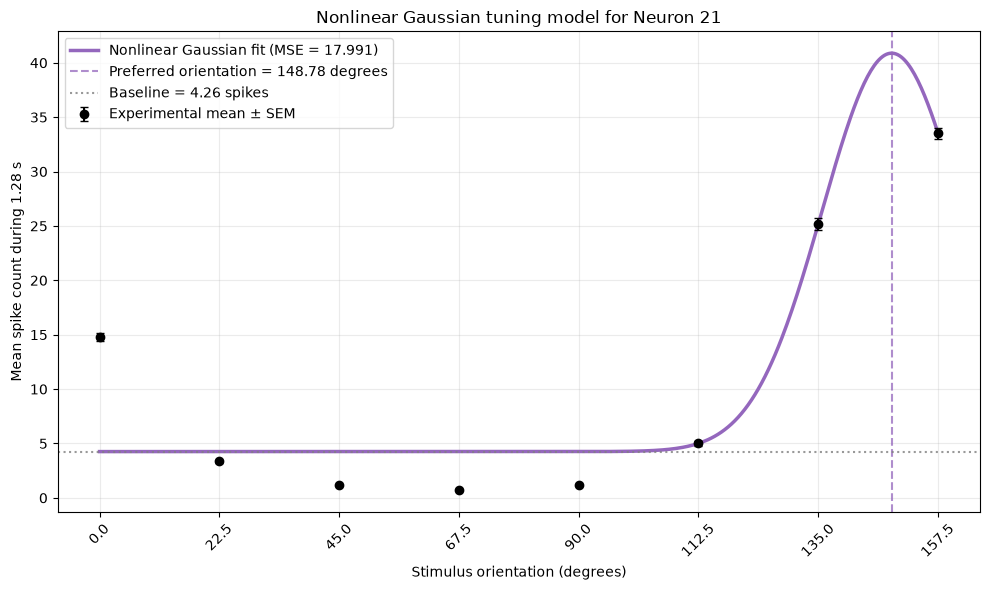

In [32]:
import matplotlib.pyplot as plt

gaussian_theta_dense = np.linspace(theta.min(), theta.max(), 500)
gaussian_response_dense = gaussian_tuning(
    gaussian_theta_dense, *gaussian_parameters
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    theta,
    response,
    yerr=selected_sem,
    color="black",
    marker="o",
    linestyle="none",
    markersize=6,
    capsize=3,
    label=r"Experimental mean $\pm$ SEM",
    zorder=5,
)
ax.plot(
    gaussian_theta_dense,
    gaussian_response_dense,
    color="tab:purple",
    linewidth=2.5,
    label=f"Nonlinear Gaussian fit (MSE = {gaussian_mse:.3f})",
)
ax.axvline(
    mu_hat,
    color="tab:purple",
    linestyle="--",
    alpha=0.75,
    label=f"Preferred orientation = {mu_hat:.2f} degrees",
)
ax.axhline(
    B_hat,
    color="gray",
    linestyle=":",
    alpha=0.8,
    label=f"Baseline = {B_hat:.2f} spikes",
)

ax.set_title("Nonlinear Gaussian tuning model for Neuron 21")
ax.set_xlabel("Stimulus orientation (degrees)")
ax.set_ylabel("Mean spike count during 1.28 s")
ax.set_xticks(theta)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig("nonlinear_gaussian_fit_neuron21.png", dpi=300, bbox_inches="tight")
plt.show()

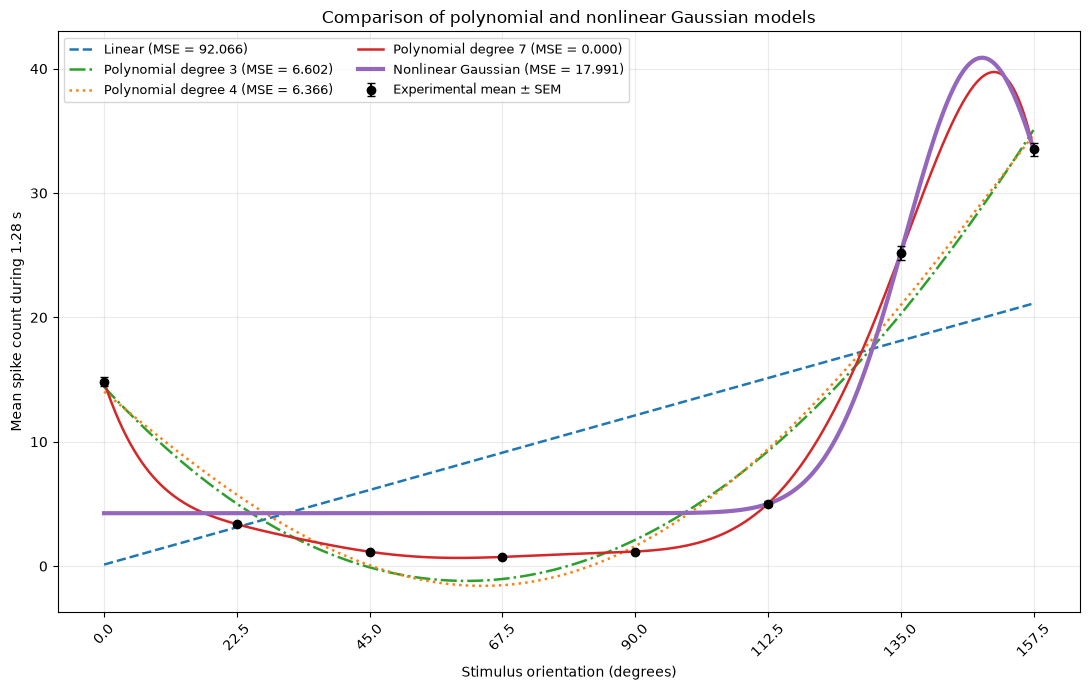

In [33]:
import matplotlib.pyplot as plt

comparison_theta = np.linspace(theta.min(), theta.max(), 500)
comparison_colors = {1: "tab:blue", 3: "tab:green", 4: "tab:orange", 7: "tab:red"}
comparison_styles = {1: "--", 3: "-.", 4: ":", 7: "-"}

fig, ax = plt.subplots(figsize=(11, 7))

ax.errorbar(
    theta,
    response,
    yerr=selected_sem,
    color="black",
    marker="o",
    linestyle="none",
    markersize=6,
    capsize=3,
    label=r"Experimental mean $\pm$ SEM",
    zorder=6,
)

for degree in polynomial_degrees:
    model_name = "Linear" if degree == 1 else f"Polynomial degree {degree}"
    ax.plot(
        comparison_theta,
        polynomial_models[degree](comparison_theta),
        color=comparison_colors[degree],
        linestyle=comparison_styles[degree],
        linewidth=1.8,
        label=f"{model_name} (MSE = {polynomial_mse[degree]:.3f})",
    )

ax.plot(
    comparison_theta,
    gaussian_tuning(comparison_theta, *gaussian_parameters),
    color="tab:purple",
    linewidth=3.0,
    label=f"Nonlinear Gaussian (MSE = {gaussian_mse:.3f})",
    zorder=5,
)

ax.set_title("Comparison of polynomial and nonlinear Gaussian models")
ax.set_xlabel("Stimulus orientation (degrees)")
ax.set_ylabel("Mean spike count during 1.28 s")
ax.set_xticks(theta)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=9)

fig.tight_layout()
fig.savefig("polynomial_vs_gaussian_neuron21.png", dpi=300, bbox_inches="tight")
plt.show()

## Circular von Mises regression

In [34]:
import numpy as np
from scipy.optimize import curve_fit


def von_mises_tuning(
    theta_degrees, baseline, amplitude, preferred_orientation, concentration
):
    """Circular orientation-tuning model from the assignment."""
    angular_difference = np.deg2rad(theta_degrees - preferred_orientation)
    return baseline + amplitude * np.exp(
        concentration * np.cos(2.0 * angular_difference)
    )


assert theta.shape == response.shape == (8,)

initial_baseline = float(max(0.0, response.min()))
initial_peak_increment = float(max(np.ptp(response), 1e-6))
initial_mu_values = np.r_[theta, 179.999]
initial_kappa_values = (0.25, 0.5, 1.0, 2.0, 4.0, 8.0)

# kappa is bounded at 20 only to keep exp(kappa) numerically well behaved.
# The fitted value is checked below to ensure that it is not near this bound.
lower_bounds = (0.0, 0.0, 0.0, 0.0)
upper_bounds = (np.inf, np.inf, 180.0, 20.0)
von_mises_candidates = []

for initial_mu in initial_mu_values:
    for initial_kappa in initial_kappa_values:
        # In the assignment's parameterization, the peak contribution is
        # amplitude * exp(kappa). This initialization keeps it comparable
        # across the different starting values of kappa.
        initial_amplitude = max(
            initial_peak_increment * np.exp(-initial_kappa), 1e-8
        )
        initial_parameters = (
            initial_baseline,
            initial_amplitude,
            float(initial_mu),
            initial_kappa,
        )

        try:
            fitted_parameters, covariance = curve_fit(
                von_mises_tuning,
                theta,
                response,
                p0=initial_parameters,
                bounds=(lower_bounds, upper_bounds),
                maxfev=200_000,
            )
        except (RuntimeError, ValueError, FloatingPointError):
            continue

        candidate_prediction = von_mises_tuning(theta, *fitted_parameters)
        candidate_mse = float(np.mean((response - candidate_prediction) ** 2))

        if np.all(np.isfinite(fitted_parameters)) and np.isfinite(candidate_mse):
            von_mises_candidates.append(
                (candidate_mse, fitted_parameters, covariance)
            )

if not von_mises_candidates:
    raise RuntimeError("The circular von Mises fit did not converge.")

von_mises_mse, von_mises_parameters, von_mises_covariance = min(
    von_mises_candidates, key=lambda candidate: candidate[0]
)

vm_B_hat, vm_A_hat, vm_mu_hat, vm_kappa_hat = von_mises_parameters
von_mises_predictions = von_mises_tuning(theta, *von_mises_parameters)
von_mises_peak_response = vm_B_hat + vm_A_hat * np.exp(vm_kappa_hat)
von_mises_minimum_response = vm_B_hat + vm_A_hat * np.exp(-vm_kappa_hat)

assert von_mises_predictions.shape == response.shape
assert np.all(np.isfinite(von_mises_predictions))
assert vm_kappa_hat < 0.95 * upper_bounds[3]
assert np.isclose(
    von_mises_tuning(0.0, *von_mises_parameters),
    von_mises_tuning(180.0, *von_mises_parameters),
)

print("Circular von Mises fit for Neuron 21")
print(f"B (baseline):                {vm_B_hat:.6f} spikes")
print(f"A (scale parameter):         {vm_A_hat:.6f} spikes")
print(f"mu (preferred orientation):  {vm_mu_hat:.6f} degrees")
print(f"kappa (concentration):       {vm_kappa_hat:.6f}")
print(f"Predicted peak response:     {von_mises_peak_response:.6f} spikes")
print(f"Predicted minimum response:  {von_mises_minimum_response:.6f} spikes")
print(f"MSE:                         {von_mises_mse:.6f}")
print(f"Gaussian MSE:                {gaussian_mse:.6f}")

Circular von Mises fit for Neuron 21
B (baseline):                0.000000 spikes
A (scale parameter):         4.424697 spikes
mu (preferred orientation):  152.356694 degrees
kappa (concentration):       2.074355
Predicted peak response:     35.217997 spikes
Predicted minimum response:  0.555907 spikes
MSE:                         0.417598
Gaussian MSE:                17.990826


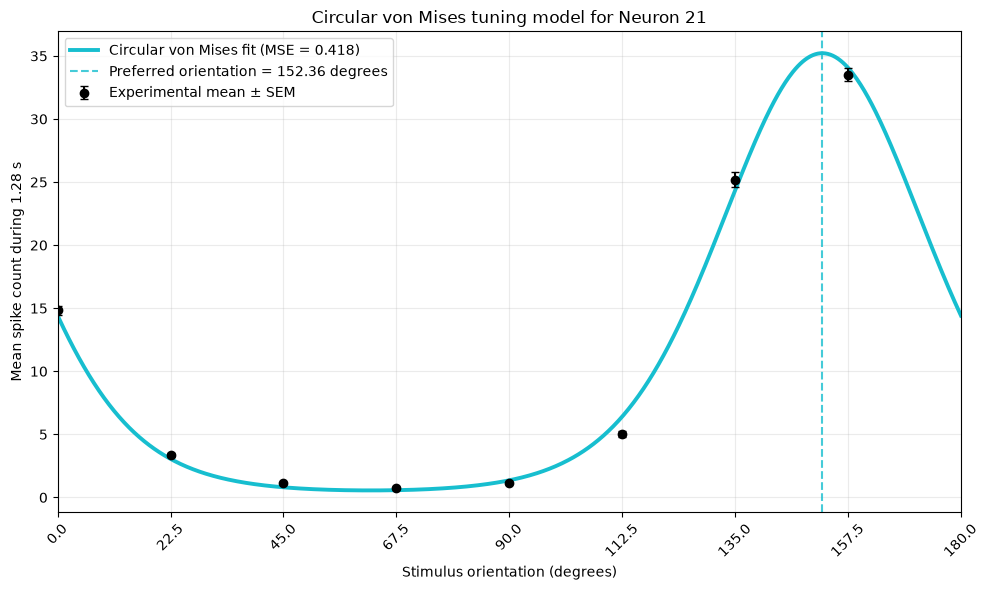

In [35]:
import matplotlib.pyplot as plt

circular_theta_dense = np.linspace(0.0, 180.0, 721)
von_mises_response_dense = von_mises_tuning(
    circular_theta_dense, *von_mises_parameters
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    theta,
    response,
    yerr=selected_sem,
    color="black",
    marker="o",
    linestyle="none",
    markersize=6,
    capsize=3,
    label=r"Experimental mean $\pm$ SEM",
    zorder=5,
)
ax.plot(
    circular_theta_dense,
    von_mises_response_dense,
    color="tab:cyan",
    linewidth=2.8,
    label=f"Circular von Mises fit (MSE = {von_mises_mse:.3f})",
)
ax.axvline(
    vm_mu_hat,
    color="tab:cyan",
    linestyle="--",
    alpha=0.8,
    label=f"Preferred orientation = {vm_mu_hat:.2f} degrees",
)

ax.set_title("Circular von Mises tuning model for Neuron 21")
ax.set_xlabel("Stimulus orientation (degrees)")
ax.set_ylabel("Mean spike count during 1.28 s")
ax.set_xlim(0.0, 180.0)
ax.set_xticks(np.r_[theta, 180.0])
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig("von_mises_fit_neuron21.png", dpi=300, bbox_inches="tight")
plt.show()

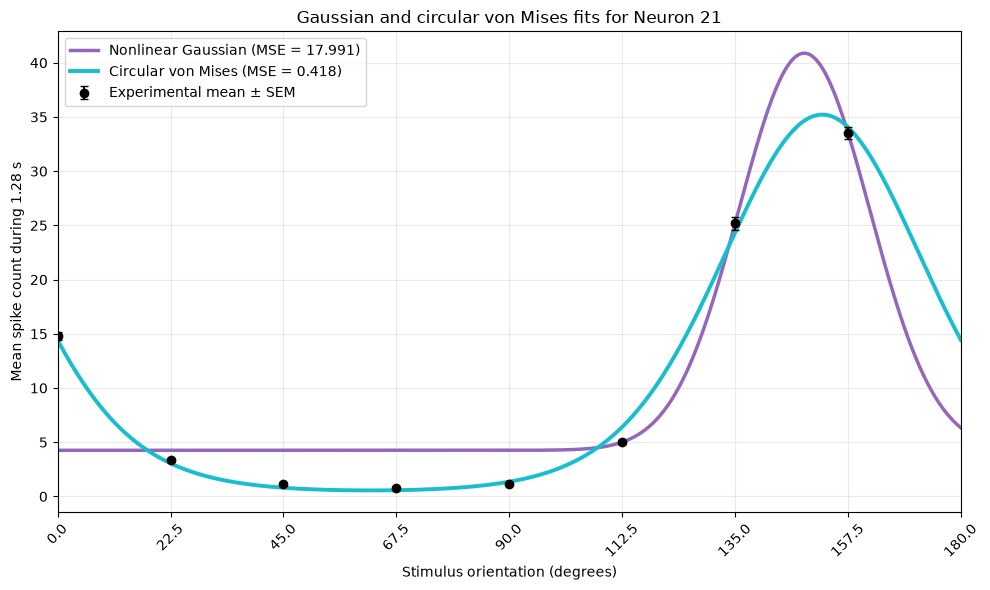

In [36]:
import matplotlib.pyplot as plt

circular_comparison_theta = np.linspace(0.0, 180.0, 721)

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    theta,
    response,
    yerr=selected_sem,
    color="black",
    marker="o",
    linestyle="none",
    markersize=6,
    capsize=3,
    label=r"Experimental mean $\pm$ SEM",
    zorder=5,
)
ax.plot(
    circular_comparison_theta,
    gaussian_tuning(circular_comparison_theta, *gaussian_parameters),
    color="tab:purple",
    linewidth=2.5,
    label=f"Nonlinear Gaussian (MSE = {gaussian_mse:.3f})",
)
ax.plot(
    circular_comparison_theta,
    von_mises_tuning(circular_comparison_theta, *von_mises_parameters),
    color="tab:cyan",
    linewidth=2.8,
    label=f"Circular von Mises (MSE = {von_mises_mse:.3f})",
)

ax.set_title("Gaussian and circular von Mises fits for Neuron 21")
ax.set_xlabel("Stimulus orientation (degrees)")
ax.set_ylabel("Mean spike count during 1.28 s")
ax.set_xlim(0.0, 180.0)
ax.set_xticks(np.r_[theta, 180.0])
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig("gaussian_vs_von_mises_neuron21.png", dpi=300, bbox_inches="tight")
plt.show()

## Noisy-neuron selection

In [37]:
import numpy as np

# Recover the sample SD across trials from SEM = SD / sqrt(number of trials).
within_orientation_sd = sem_responses * np.sqrt(
    trials_per_orientation[np.newaxis, :]
)

# Pool the eight within-orientation sample variances. The weights are their
# degrees of freedom, N_o - 1. This excludes differences between orientation means.
orientation_df = trials_per_orientation - 1
pooled_within_orientation_sd = np.sqrt(
    np.sum(
        orientation_df[np.newaxis, :] * within_orientation_sd**2, axis=1
    )
    / orientation_df.sum()
)

orientation_modulation = np.ptp(mean_responses, axis=1)
mean_orientation_sem = sem_responses.mean(axis=1)
noise_to_modulation = np.divide(
    pooled_within_orientation_sd,
    orientation_modulation,
    out=np.full(n_neurons, np.inf, dtype=float),
    where=orientation_modulation > 0,
)

original_neuron_index = selected_neuron_index  # Neuron 21, Python index 20
noisy_neuron_indices = np.array([73, 100])      # Neurons 74 and 101
comparison_neuron_indices = np.r_[original_neuron_index, noisy_neuron_indices]

# Both added neurons must have at least twice the pooled trial SD of Neuron 21.
assert np.all(
    pooled_within_orientation_sd[noisy_neuron_indices]
    >= 2.0 * pooled_within_orientation_sd[original_neuron_index]
)

print(
    f"{'Neuron':>6} {'Pooled SD':>12} {'Mean SEM':>12} "
    f"{'Modulation':>12} {'Noise/mod.':>12} {'SD / original':>14}"
)
for neuron_index in comparison_neuron_indices:
    sd_relative_to_original = (
        pooled_within_orientation_sd[neuron_index]
        / pooled_within_orientation_sd[original_neuron_index]
    )
    print(
        f"{neuron_index + 1:>6d} "
        f"{pooled_within_orientation_sd[neuron_index]:>12.3f} "
        f"{mean_orientation_sem[neuron_index]:>12.3f} "
        f"{orientation_modulation[neuron_index]:>12.3f} "
        f"{noise_to_modulation[neuron_index]:>12.3f} "
        f"{sd_relative_to_original:>14.2f}"
    )

Neuron    Pooled SD     Mean SEM   Modulation   Noise/mod.  SD / original
    21        6.421        0.253       32.785        0.196           1.00
    74       12.962        0.636       16.065        0.807           2.02
   101       18.221        0.904       31.092        0.586           2.84


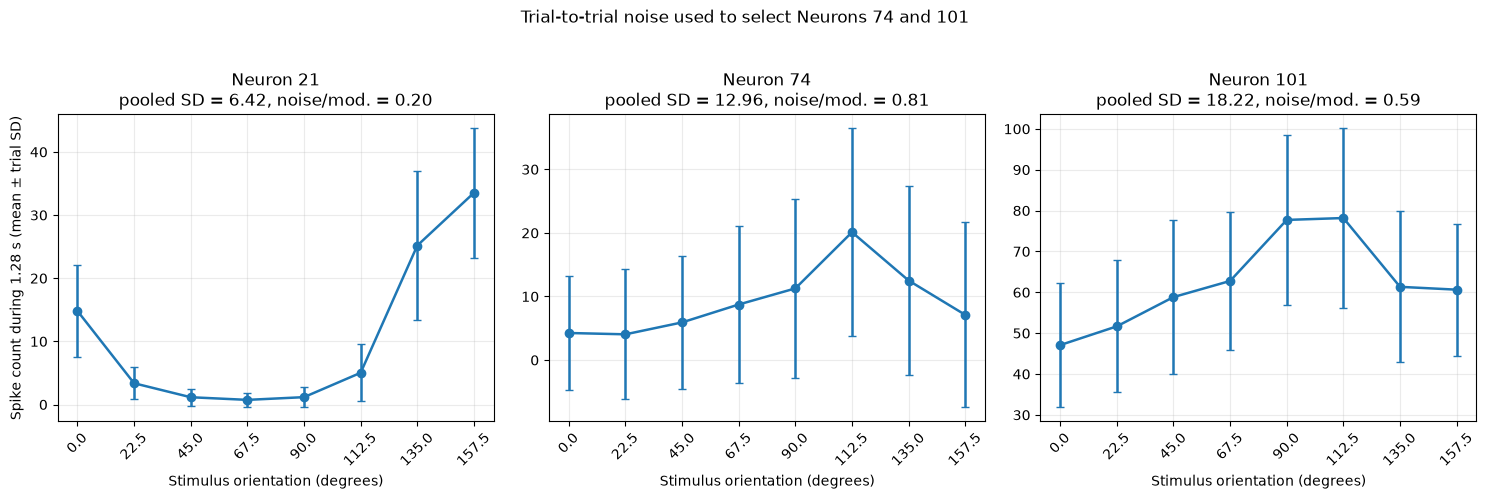

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

for ax, neuron_index in zip(axes, comparison_neuron_indices):
    ax.errorbar(
        orientations_deg,
        mean_responses[neuron_index],
        yerr=within_orientation_sd[neuron_index],
        color="tab:blue",
        marker="o",
        linewidth=1.8,
        capsize=3,
    )
    ax.set_title(
        f"Neuron {neuron_index + 1}\n"
        f"pooled SD = {pooled_within_orientation_sd[neuron_index]:.2f}, "
        f"noise/mod. = {noise_to_modulation[neuron_index]:.2f}"
    )
    ax.set_xlabel("Stimulus orientation (degrees)")
    ax.set_xticks(orientations_deg)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)

axes[0].set_ylabel(r"Spike count during 1.28 s (mean $\pm$ trial SD)")
fig.suptitle("Trial-to-trial noise used to select Neurons 74 and 101", y=1.03)
fig.tight_layout()
fig.savefig("noisy_neuron_selection.png", dpi=300, bbox_inches="tight")
plt.show()

## Model comparison for noisy neurons

In [39]:
import numpy as np
from numpy.polynomial import Polynomial
from scipy.optimize import curve_fit


def fit_gaussian_with_multiple_starts(theta_values, response_values):
    """Return the converged Gaussian fit with the smallest MSE."""
    candidates = []
    initial_baseline = float(max(0.0, response_values.min()))
    initial_amplitude = float(max(np.ptp(response_values), 1e-6))

    for initial_mu in theta_values:
        for initial_sigma in (10.0, 30.0, 60.0):
            try:
                parameters, covariance = curve_fit(
                    gaussian_tuning,
                    theta_values,
                    response_values,
                    p0=(
                        initial_baseline,
                        initial_amplitude,
                        float(initial_mu),
                        initial_sigma,
                    ),
                    bounds=(
                        (0.0, 0.0, 0.0, 1e-6),
                        (np.inf, np.inf, 180.0, 180.0),
                    ),
                    maxfev=100_000,
                )
            except (RuntimeError, ValueError, FloatingPointError):
                continue

            prediction = gaussian_tuning(theta_values, *parameters)
            mse = float(np.mean((response_values - prediction) ** 2))
            if np.all(np.isfinite(parameters)) and np.isfinite(mse):
                candidates.append((mse, parameters, covariance))

    if not candidates:
        raise RuntimeError("No Gaussian initialization converged.")
    return min(candidates, key=lambda candidate: candidate[0])


def fit_von_mises_with_multiple_starts(theta_values, response_values):
    """Return the converged circular von Mises fit with the smallest MSE."""
    candidates = []
    initial_baseline = float(max(0.0, response_values.min()))
    initial_peak_increment = float(max(np.ptp(response_values), 1e-6))

    for initial_mu in np.r_[theta_values, 179.999]:
        for initial_kappa in (0.25, 0.5, 1.0, 2.0, 4.0, 8.0):
            initial_amplitude = max(
                initial_peak_increment * np.exp(-initial_kappa), 1e-8
            )
            try:
                parameters, covariance = curve_fit(
                    von_mises_tuning,
                    theta_values,
                    response_values,
                    p0=(
                        initial_baseline,
                        initial_amplitude,
                        float(initial_mu),
                        initial_kappa,
                    ),
                    bounds=(
                        (0.0, 0.0, 0.0, 0.0),
                        (np.inf, np.inf, 180.0, 20.0),
                    ),
                    maxfev=200_000,
                )
            except (RuntimeError, ValueError, FloatingPointError):
                continue

            prediction = von_mises_tuning(theta_values, *parameters)
            mse = float(np.mean((response_values - prediction) ** 2))
            if np.all(np.isfinite(parameters)) and np.isfinite(mse):
                candidates.append((mse, parameters, covariance))

    if not candidates:
        raise RuntimeError("No von Mises initialization converged.")
    return min(candidates, key=lambda candidate: candidate[0])


noisy_model_results = {}

for neuron_index in noisy_neuron_indices:
    neuron_number = int(neuron_index + 1)
    neuron_response = np.asarray(mean_responses[neuron_index], dtype=float)

    polynomial_model = Polynomial.fit(theta, neuron_response, deg=7)
    polynomial_prediction = polynomial_model(theta)
    polynomial_mse_value = float(
        np.mean((neuron_response - polynomial_prediction) ** 2)
    )

    gaussian_mse_value, gaussian_params, gaussian_covariance = (
        fit_gaussian_with_multiple_starts(theta, neuron_response)
    )
    gaussian_prediction = gaussian_tuning(theta, *gaussian_params)

    von_mises_mse_value, von_mises_params, von_mises_covariance = (
        fit_von_mises_with_multiple_starts(theta, neuron_response)
    )
    von_mises_prediction = von_mises_tuning(theta, *von_mises_params)

    noisy_model_results[neuron_number] = {
        "response": neuron_response,
        "sem": np.asarray(sem_responses[neuron_index], dtype=float),
        "Polynomial degree 7": {
            "model": polynomial_model,
            "prediction": polynomial_prediction,
            "mse": polynomial_mse_value,
        },
        "Gaussian": {
            "parameters": gaussian_params,
            "covariance": gaussian_covariance,
            "prediction": gaussian_prediction,
            "mse": gaussian_mse_value,
        },
        "von Mises": {
            "parameters": von_mises_params,
            "covariance": von_mises_covariance,
            "prediction": von_mises_prediction,
            "mse": von_mises_mse_value,
        },
    }

    assert polynomial_mse_value < 1e-20
    assert np.all(np.isfinite(gaussian_prediction))
    assert np.all(np.isfinite(von_mises_prediction))

print(f"{'Neuron':>6} {'Model':<24} {'MSE':>14}")
for neuron_number, results in noisy_model_results.items():
    for model_name in ("Polynomial degree 7", "Gaussian", "von Mises"):
        print(
            f"{neuron_number:>6d} {model_name:<24} "
            f"{results[model_name]['mse']:>14.6e}"
        )

print("\nFitted nonlinear parameters: [B, A, mu, width/concentration]")
for neuron_number, results in noisy_model_results.items():
    print(
        f"Neuron {neuron_number} Gaussian: "
        f"{np.round(results['Gaussian']['parameters'], 6)}"
    )
    print(
        f"Neuron {neuron_number} von Mises: "
        f"{np.round(results['von Mises']['parameters'], 6)}"
    )

Neuron Model                               MSE
    74 Polynomial degree 7        1.467981e-26
    74 Gaussian                   1.428919e+00
    74 von Mises                  1.194306e+00
   101 Polynomial degree 7        5.906990e-27
   101 Gaussian                   9.748040e+00
   101 von Mises                  9.972122e+00

Fitted nonlinear parameters: [B, A, mu, width/concentration]
Neuron 74 Gaussian: [  5.403317  14.103936 113.343387  19.585866]
Neuron 74 von Mises: [  5.009516   1.595732 113.225978   2.212877]
Neuron 101 Gaussian: [ 49.669468  28.1813   101.253524  32.718698]
Neuron 101 von Mises: [ 46.978444  12.16719  100.855156   0.984894]


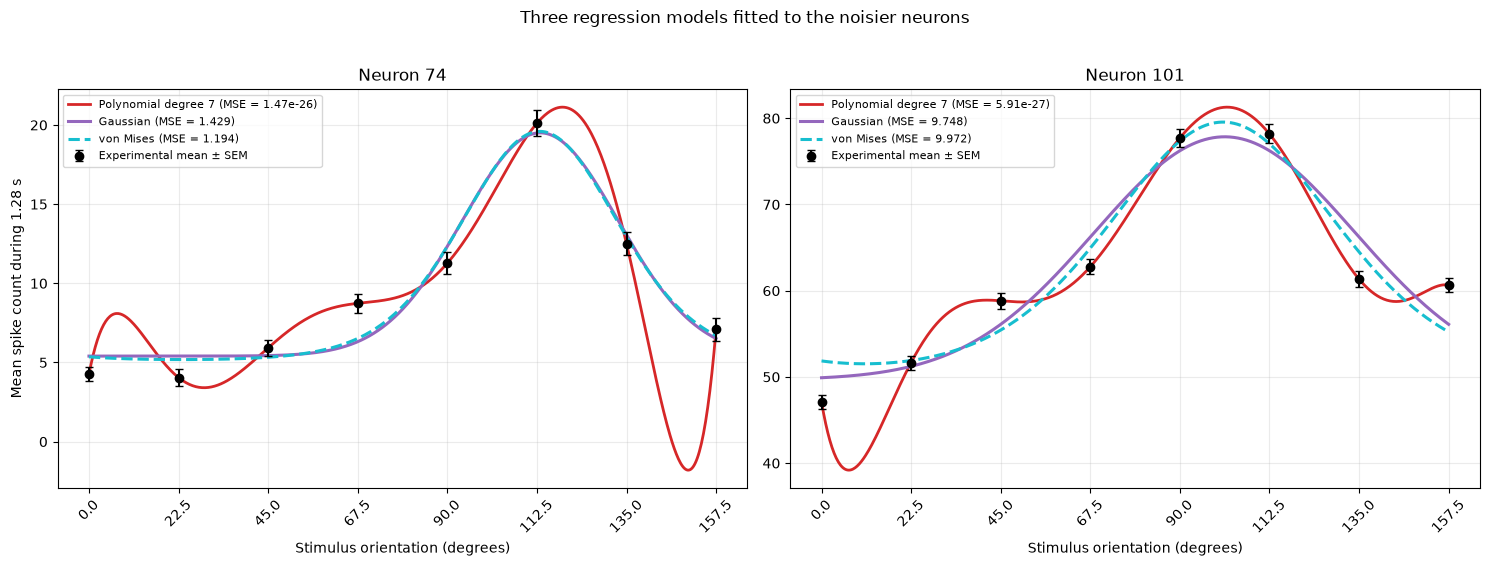

In [40]:
import matplotlib.pyplot as plt

fit_theta_dense = np.linspace(theta.min(), theta.max(), 600)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, neuron_number in zip(axes, (74, 101)):
    results = noisy_model_results[neuron_number]

    ax.errorbar(
        theta,
        results["response"],
        yerr=results["sem"],
        color="black",
        marker="o",
        linestyle="none",
        markersize=6,
        capsize=3,
        label=r"Experimental mean $\pm$ SEM",
        zorder=5,
    )
    ax.plot(
        fit_theta_dense,
        results["Polynomial degree 7"]["model"](fit_theta_dense),
        color="tab:red",
        linewidth=2.0,
        label=(
            "Polynomial degree 7 "
            f"(MSE = {results['Polynomial degree 7']['mse']:.2e})"
        ),
    )
    ax.plot(
        fit_theta_dense,
        gaussian_tuning(
            fit_theta_dense, *results["Gaussian"]["parameters"]
        ),
        color="tab:purple",
        linewidth=2.2,
        label=f"Gaussian (MSE = {results['Gaussian']['mse']:.3f})",
    )
    ax.plot(
        fit_theta_dense,
        von_mises_tuning(
            fit_theta_dense, *results["von Mises"]["parameters"]
        ),
        color="tab:cyan",
        linewidth=2.2,
        linestyle="--",
        label=f"von Mises (MSE = {results['von Mises']['mse']:.3f})",
    )

    ax.set_title(f"Neuron {neuron_number}")
    ax.set_xlabel("Stimulus orientation (degrees)")
    ax.set_xticks(theta)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Mean spike count during 1.28 s")
fig.suptitle("Three regression models fitted to the noisier neurons", y=1.02)
fig.tight_layout()
fig.savefig("three_model_fits_noisy_neurons.png", dpi=300, bbox_inches="tight")
plt.show()